In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

sns.set(style="whitegrid")

In [12]:
# Load Titanic dataset
titanic = fetch_openml(name="titanic", version=1, as_frame=True)

# Create DataFrame
df = titanic.frame

# Display first 5 rows
df.head()

C:\Users\kvafs\anaconda3\Lib\site-packages\sklearn\datasets\_openml.py:1002: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1.0,1,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [13]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe(include="all"))

Shape: (1309, 14)

Columns:
Index(['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   float64 
 1   survived   1309 non-null   category
 2   name       1309 non-null   object  
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   float64 
 6   parch      1309 non-null   float64 
 7   ticket     1309 non-null   object  
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    object  
 10  embarked   1307 non-null   category
 11  boat       486 non-null    object  
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    object  
dtypes: category(3),

In [14]:
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])

df["survived"] = df["survived"].astype(int)

In [15]:
numeric_df = df.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

print(corr_matrix)

            pclass  survived       age     sibsp     parch      fare      body
pclass    1.000000 -0.312469 -0.377908  0.060832  0.018322 -0.558683 -0.034642
survived -0.312469  1.000000 -0.043818 -0.027825  0.082660  0.244414       NaN
age      -0.377908 -0.043818  1.000000 -0.189972 -0.125851  0.178182  0.059114
sibsp     0.060832 -0.027825 -0.189972  1.000000  0.373587  0.160349 -0.099961
parch     0.018322  0.082660 -0.125851  0.373587  1.000000  0.221635  0.051099
fare     -0.558683  0.244414  0.178182  0.160349  0.221635  1.000000 -0.046432
body     -0.034642       NaN  0.059114 -0.099961  0.051099 -0.046432  1.000000


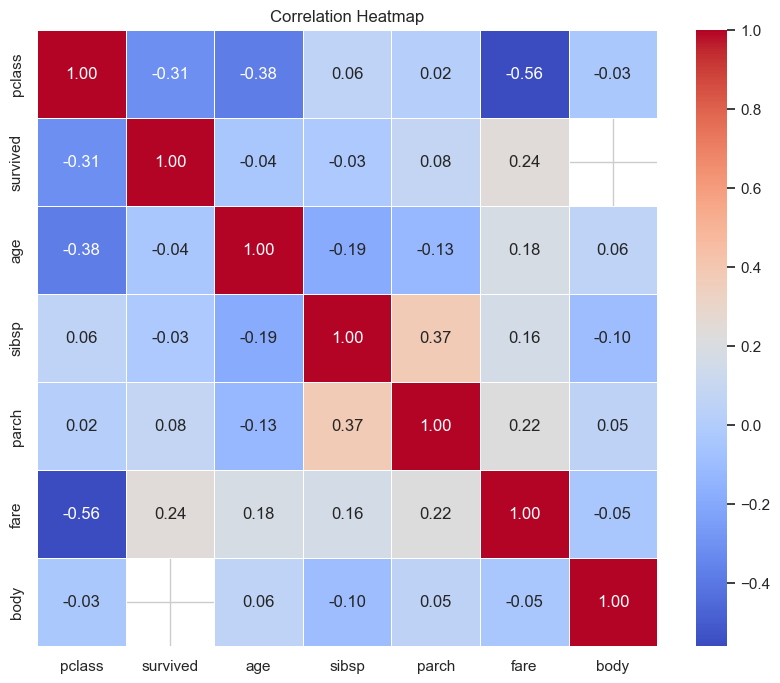

In [16]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

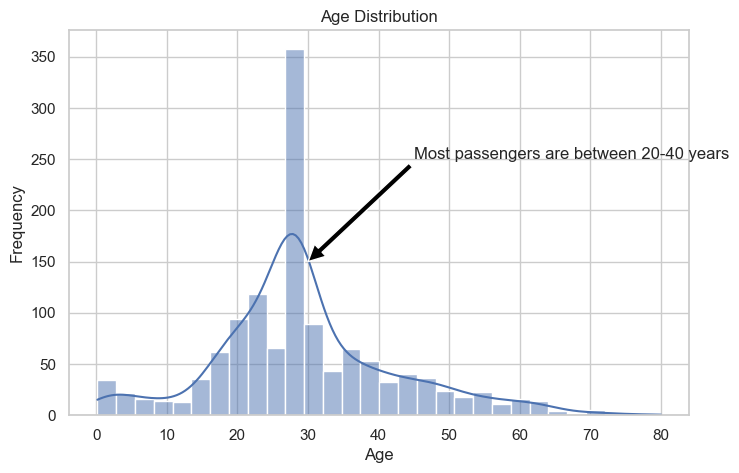

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df["age"], kde=True, bins=30)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.annotate(
    "Most passengers are between 20-40 years",
    xy=(30,150),
    xytext=(45,250),
    arrowprops=dict(facecolor="black")
)

plt.show()

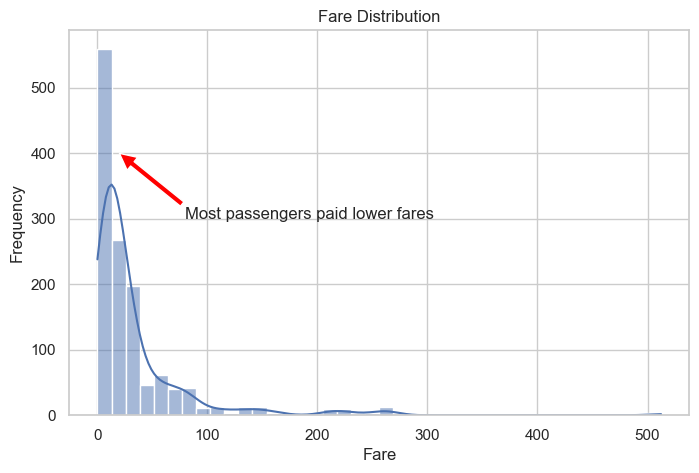

In [18]:
plt.figure(figsize=(8,5))

sns.histplot(df["fare"], kde=True, bins=40)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.annotate(
    "Most passengers paid lower fares",
    xy=(20,400),
    xytext=(80,300),
    arrowprops=dict(facecolor="red")
)

plt.show()

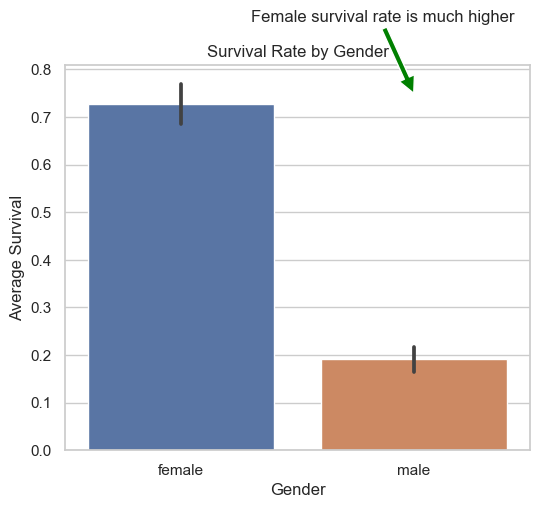

In [19]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=df,
    x="sex",
    y="survived"
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Survival")

plt.annotate(
    "Female survival rate is much higher",
    xy=(1,0.75),
    xytext=(0.3,0.9),
    arrowprops=dict(facecolor="green")
)

plt.show()

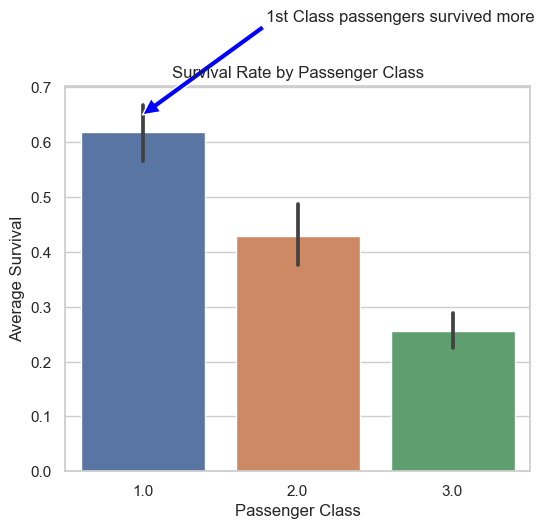

In [20]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=df,
    x="pclass",
    y="survived"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Survival")

plt.annotate(
    "1st Class passengers survived more",
    xy=(0,0.65),
    xytext=(0.8,0.82),
    arrowprops=dict(facecolor="blue")
)

plt.show() 

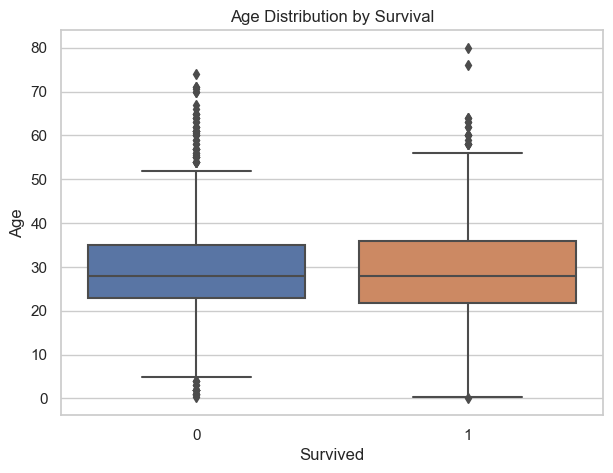

In [21]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="survived",
    y="age"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived")
plt.ylabel("Age")

plt.show()

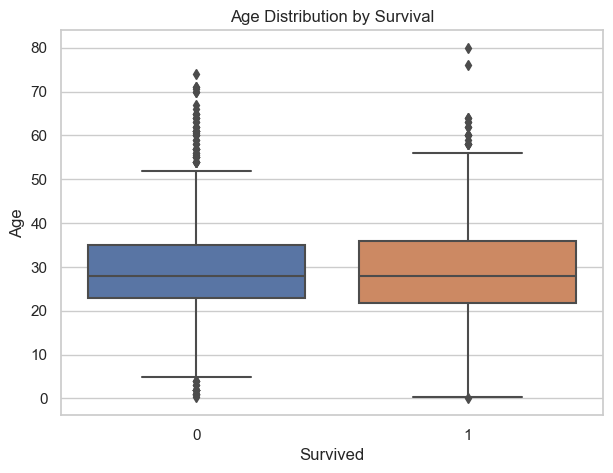

In [22]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="survived",
    y="age"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived")
plt.ylabel("Age")

plt.show()

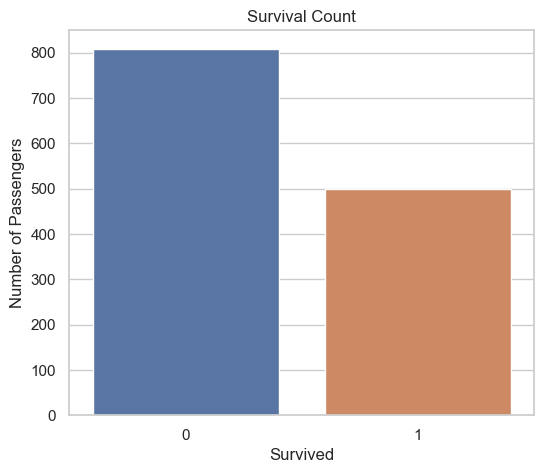

In [23]:
plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x="survived"
)

plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

C:\Users\kvafs\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


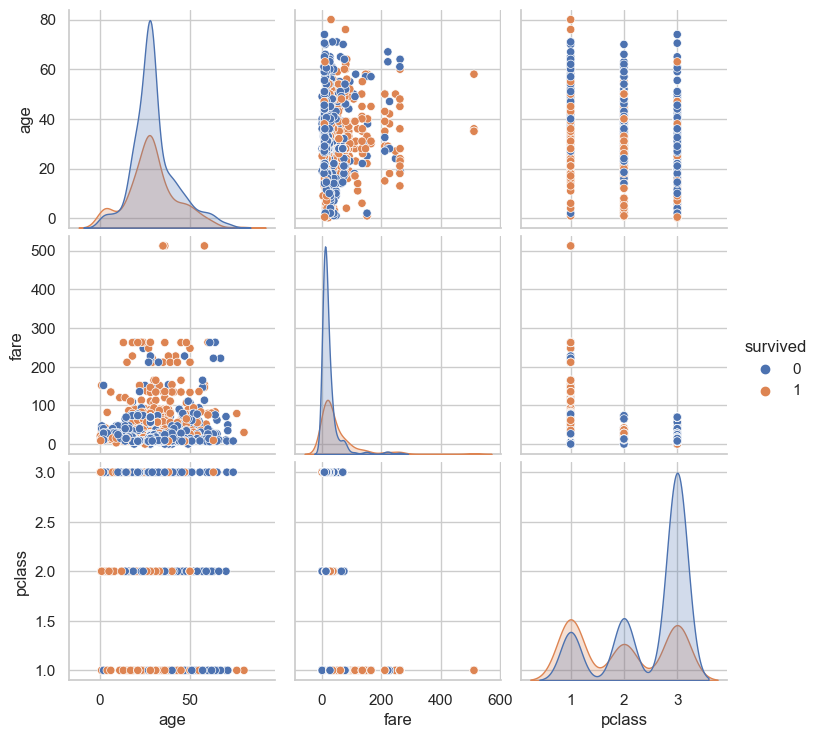

In [24]:
sns.pairplot(
    df[["age","fare","pclass","survived"]],
    hue="survived"
)

plt.show()

In [25]:
print("Correlation with Survival:\n")
print(
    corr_matrix["survived"].sort_values(ascending=False)
) 

Correlation with Survival:

survived    1.000000
fare        0.244414
parch       0.082660
sibsp      -0.027825
age        -0.043818
pclass     -0.312469
body             NaN
Name: survived, dtype: float64


In [26]:
print("Key Findings")
print("- Females had a much higher survival rate than males.")
print("- Passengers in 1st class survived more frequently.")
print("- Most passengers were between 20 and 40 years old.")
print("- Fare distribution is highly right-skewed.")
print("- Passenger class has a negative correlation with survival.")
print("- Fare has a positive correlation with survival.")
print("- Age has only a weak relationship with survival.")

Key Findings
- Females had a much higher survival rate than males.
- Passengers in 1st class survived more frequently.
- Most passengers were between 20 and 40 years old.
- Fare distribution is highly right-skewed.
- Passenger class has a negative correlation with survival.
- Fare has a positive correlation with survival.
- Age has only a weak relationship with survival.
